
# ILLM Lab 1 — Language Identification for Indic Languages (IndicCorp v2)

**Goal:** Build a language identifier for 23 Indian languages (with their scripts) using
`ai4bharat/IndicCorpV2`, where the text representation (TF‑IDF with word + character
n‑grams), the classifier (multinomial / softmax logistic regression), and the evaluation
metric (macro‑F1) are **all implemented from scratch** — no `sklearn` classes are used
anywhere in the modeling pipeline.

---

## 1. Deep analysis of the assignment

Breaking the assignment statement into concrete engineering requirements:

| # | Requirement (from the prompt) | What it means concretely |
|---|---|---|
| A | Use IndicCorpV2, 23 languages incl. scripts | The dataset's `indiccorp_v2` config exposes 23 splits, each named `<lang>_<Script>` (e.g. `hin_Deva`, `tam_Taml`) or a bare code for `khasi`/`santhali`. These split names **are** the labels the assignment tells us to reuse. |
| B | Take 1000 sentences / language | IndicCorp stores **paragraphs**, not sentences → we must sentence‑tokenize first, then sample 1000 clean sentences per language. |
| C | "Take care about tokenization" | Indic scripts don't all end sentences with `.` — Devanagari/Bengali/Odia etc. use the *danda* `।` and *double danda* `॥`; Urdu/Kashmiri (Arabic script) use `۔` and `؟`. A naive `split('.')` would badly under‑segment these. We need a script‑aware sentence splitter. |
| D | 80:10:10 train/val/test, **stratified** | Split *within each language* in an 800:100:100 ratio (1000 is conveniently divisible), so every split has exactly the same per‑class distribution. |
| E | TF‑IDF: word unigrams+bigrams **and** char 2/3/4‑grams, custom‑built | No `sklearn.feature_extraction.text.TfidfVectorizer`/`CountVectorizer`. We write our own vocabulary builder, document‑frequency counter, IDF weighting and sparse matrix construction (using `scipy.sparse` purely as a storage container — the *math* is ours). |
| F | Logistic Regression, custom‑built | Since this is a 23‑class problem, "logistic regression" here means **multinomial (softmax) logistic regression**, trained with mini‑batch gradient descent, implemented with plain NumPy. |
| G | Macro‑F1 evaluation, custom‑built | Implement confusion matrix → per‑class precision/recall/F1 → macro average, all in NumPy, no `sklearn.metrics`. |

## 2. Pipeline (what this notebook executes, in order)

```
IndicCorpV2 (streamed)                 
     │  stream paragraphs per language, shuffle
     ▼
Sentence tokenizer (script-aware regex)
     │  split paragraphs → sentences, clean & de-duplicate
     ▼
1000 sentences × 23 languages  =  23,000-row labeled dataset  (label = HF split name)
     │  stratified 80/10/10 split PER language
     ▼
Train (18,400) / Val (2,300) / Test (2,300)
     │
     ▼
Custom TF-IDF Vectorizer  (word 1-2 grams + char 2/3/4-grams, fit on TRAIN only)
     │
     ▼
Custom Softmax Logistic Regression  (mini-batch gradient descent, L2 reg.)
     │
     ▼
Custom evaluation module  →  confusion matrix, per-class P/R/F1, macro-F1
     │
     ▼
Report on Validation (model selection) and held-out Test (final numbers)
```

## 3. A note on where this notebook runs

This notebook downloads data from `huggingface.co`. It was authored in a sandboxed
environment **without** internet access to the Hugging Face Hub, so the data‑download
cells could not be executed while writing it — but every other component (the sentence
tokenizer, the TF‑IDF vectorizer, the logistic regression classifier, and the evaluation
metrics) was implemented and **unit‑tested end‑to‑end on synthetic multi‑class text data**
of the same scale (23 classes, ~18–23k documents) to confirm correctness and runtime
before being placed here. Run this notebook top‑to‑bottom on a machine/Colab with normal
internet access (`pip install datasets huggingface_hub` must be able to reach
`huggingface.co`). Expected end‑to‑end runtime: a few minutes for data collection
(depends on network) + ~1–3 minutes for vectorization + training on a normal CPU.



## Section 1 — Environment Setup

We only need generic scientific‑Python libraries plus `datasets`/`huggingface_hub` for
downloading the corpus. `scipy.sparse` is used purely as an efficient **container** for
our TF‑IDF matrix (row/col/data triplets) — all the TF‑IDF *math* (term frequency,
document frequency, IDF, normalization) is written by hand in Section 7.

**No `sklearn` import appears anywhere in this notebook.**


In [1]:

# If running for the first time, uncomment to install dependencies.
# %pip install -q datasets huggingface_hub scipy numpy pandas matplotlib tqdm


import re
import math
import random
import time
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from tqdm.auto import tqdm

# The `datasets` library is only used as a DOWNLOADER for the raw IndicCorpV2 text.
# It plays no role in feature extraction, modeling, or evaluation.
from datasets import load_dataset

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Environment ready.")


Environment ready.



## Section 2 — Language Inventory (the 23 IndicCorpV2 splits)

`ai4bharat/IndicCorpV2` exposes a single HF config, `indiccorp_v2`, and within it **23
splits** — one per language‑script combination — reached via `data_dir="data/<split>"`.
We use the **exact split names as our class labels**, as instructed ("use the same
labels as given in the repository").


In [2]:

# code   : the exact HF split name / data_dir suffix -> also used as our class label
# name   : human-readable language name (for readability in plots/reports only)
# script : the writing system, noted because several languages here share a script
#          (this will matter later during error analysis: same-script languages are
#          the hardest to tell apart from character n-grams alone)
LANGUAGES = [
    {"code": "asm_Beng", "name": "Assamese",           "script": "Bengali-Assamese"},
    {"code": "ben_Beng", "name": "Bengali",             "script": "Bengali-Assamese"},
    {"code": "brx_Deva", "name": "Bodo",                "script": "Devanagari"},
    {"code": "doi_Deva", "name": "Dogri",               "script": "Devanagari"},
    {"code": "gom_Deva", "name": "Konkani (Goan)",      "script": "Devanagari"},
    {"code": "guj_Gujr", "name": "Gujarati",            "script": "Gujarati"},
    {"code": "hin_Deva", "name": "Hindi",               "script": "Devanagari"},
    {"code": "kan_Knda", "name": "Kannada",             "script": "Kannada"},
    {"code": "kas_Arab", "name": "Kashmiri",            "script": "Perso-Arabic"},
    {"code": "mai_Deva", "name": "Maithili",            "script": "Devanagari"},
    {"code": "mal_Mlym", "name": "Malayalam",           "script": "Malayalam"},
    {"code": "mar_Deva", "name": "Marathi",             "script": "Devanagari"},
    {"code": "mni_Mtei", "name": "Manipuri (Meitei)",   "script": "Meitei Mayek"},
    {"code": "npi_Deva", "name": "Nepali",              "script": "Devanagari"},
    {"code": "ory_Orya", "name": "Odia",                "script": "Odia"},
    {"code": "pan_Guru", "name": "Punjabi",             "script": "Gurmukhi"},
    {"code": "san_Deva", "name": "Sanskrit",            "script": "Devanagari"},
    {"code": "snd_Deva", "name": "Sindhi",              "script": "Devanagari"},
    {"code": "tam_Taml", "name": "Tamil",               "script": "Tamil"},
    {"code": "tel_Telu", "name": "Telugu",              "script": "Telugu"},
    {"code": "urd_Arab", "name": "Urdu",                "script": "Perso-Arabic"},
    {"code": "khasi",    "name": "Khasi",               "script": "Latin"},
    {"code": "santhali", "name": "Santali",             "script": "Ol Chiki"},
]

assert len(LANGUAGES) == 23, "Assignment specifies exactly 23 languages."
LABELS = [l["code"] for l in LANGUAGES]          # our class labels, in a fixed order
LABEL2ID = {c: i for i, c in enumerate(LABELS)}  # label -> integer id
ID2LABEL = {i: c for c, i in LABEL2ID.items()}   # integer id -> label

pd.DataFrame(LANGUAGES)


,code,name,script
0,asm_Beng,Assamese,Bengali-Assamese
1,ben_Beng,Bengali,Bengali-Assamese
2,brx_Deva,Bodo,Devanagari
3,doi_Deva,Dogri,Devanagari
4,gom_Deva,Konkani (Goan),Devanagari
5,guj_Gujr,Gujarati,Gujarati
6,hin_Deva,Hindi,Devanagari
7,kan_Knda,Kannada,Kannada
8,kas_Arab,Kashmiri,Perso-Arabic
9,mai_Deva,Maithili,Devanagari



## Section 3 — Script‑aware Sentence Tokenizer

Each row in IndicCorpV2 is a **paragraph** (often several sentences long), not a single
sentence. Splitting on plain English punctuation (`.`, `!`, `?`) alone would fail for
scripts that mark sentence boundaries with:

* `।` U+0964 DEVANAGARI DANDA — used by Hindi, Marathi, Nepali, Sanskrit, Bodo, Dogri,
  Maithili, Sindhi (Deva), Bengali/Assamese, Odia, Gujarati, Punjabi, and others.
* `॥` U+0965 DEVANAGARI DOUBLE DANDA — verse/section end, same family of languages.
* `۔` U+06D4 ARABIC FULL STOP and `؟` U+061F ARABIC QUESTION MARK — Urdu, Kashmiri.

Our tokenizer therefore splits on **any** of `{. ! ? । ॥ ۔ ؟}`, keeps the punctuation
attached to the sentence it closes (via a look‑behind), collapses whitespace, drops
empty fragments, and finally filters out sentences that are too short (junk fragments /
headings / bullet numbers) or too long (mis‑joined paragraphs) to be a reasonable
"sentence" sample.


In [3]:

# Compile once: split the text right AFTER any sentence-ending punctuation mark,
# as long as it is followed by whitespace. The look-behind `(?<=...)` means the
# punctuation itself stays attached to the sentence that precedes the split point.
_SENTENCE_END = re.compile(r'(?<=[।॥.!?؟۔])\s+')

# Junk-prefix patterns often seen in scraped news paragraphs (bullet markers,
# leading serial numbers like "12." or ">>", stray pipe characters, etc.)
_LEADING_JUNK = re.compile(r'^(?:[>*\-•●▪·|]+|\(?\d{1,3}[.)]\s*)+')

MIN_SENT_CHARS = 20     # drop very short fragments (headings, stray tokens)
MAX_SENT_CHARS = 400    # drop pathologically long "sentences" (mis-segmented paragraphs)
MIN_SENT_WORDS = 4      # require a minimal amount of linguistic content


def sentence_tokenize(paragraph: str):
    """Split a paragraph into a list of cleaned sentences.

    Steps:
      1. Normalise whitespace (newlines/tabs/multiple spaces -> single space).
      2. Split on the multi-script sentence-final punctuation set.
      3. Strip leading bullet/number junk left over from web scraping.
      4. Filter by character-length and word-count bounds.
    """
    if not isinstance(paragraph, str) or not paragraph.strip():
        return []

    text = re.sub(r'\s+', ' ', paragraph).strip()
    raw_sentences = _SENTENCE_END.split(text)

    cleaned = []
    for s in raw_sentences:
        s = s.strip()
        s = _LEADING_JUNK.sub('', s).strip()
        if not s:
            continue
        n_chars = len(s)
        n_words = len(s.split())
        if MIN_SENT_CHARS <= n_chars <= MAX_SENT_CHARS and n_words >= MIN_SENT_WORDS:
            cleaned.append(s)
    return cleaned


# --- quick self-test on multi-script mock paragraphs -------------------------------
_test_cases = [
    "यह पहला वाक्य है और इसमें काफी शब्द हैं। यह दूसरा वाक्य है जो लंबा है॥ यह तीसरा वाक्य है और यह भी लंबा है!",
    "This is the first test sentence with enough words. This is the second one, also long enough? Yes indeed it truly is!",
    "یہ پہلا جملہ ہے اور اس میں کافی الفاظ ہیں۔ یہ دوسرا جملہ ہے جو کافی لمبا ہے؟",
]
for tc in _test_cases:
    print(sentence_tokenize(tc))


['यह पहला वाक्य है और इसमें काफी शब्द हैं।', 'यह दूसरा वाक्य है जो लंबा है॥', 'यह तीसरा वाक्य है और यह भी लंबा है!']
['This is the first test sentence with enough words.', 'This is the second one, also long enough?', 'Yes indeed it truly is!']
['یہ پہلا جملہ ہے اور اس میں کافی الفاظ ہیں۔', 'یہ دوسرا جملہ ہے جو کافی لمبا ہے؟']



## Section 4 — Building the Dataset (1000 sentences × 23 languages)

For each language split we:

1. Open the split in **streaming mode** (`streaming=True`) so we never download an
   entire multi‑gigabyte language shard just to sample 1000 sentences from it.
2. Apply a **shuffle buffer** so we are not just reading the first N paragraphs on disk
   (which could be biased, e.g. all from one source/time period).
3. Read paragraphs one at a time, sentence‑tokenize each with Section 3's function,
   and accumulate clean, unique sentences until we have comfortably more than 1000.
4. Shuffle the collected sentences and keep exactly the first 1000.

This is wrapped in `collect_sentences_for_language()`, called once per language in a
loop, with a progress bar. The final result is saved to a CSV so the rest of the
notebook (and any re‑run) does not need to re‑hit the network.


In [5]:
import os
import pandas as pd
from huggingface_hub import HfFileSystem
import random
from tqdm.auto import tqdm

# Mapping based directly on the dataset's README
FILE_MAP = {
    "asm_Beng": "as.txt", "ben_Beng": "bn.txt", "brx_Deva": "bd.txt",
    "doi_Deva": "dg.txt", "gom_Deva": "gom.txt", "guj_Gujr": "gu.txt",
    "hin_Deva": "hi-", "kan_Knda": "kn.txt", "kas_Arab": "ks.txt",
    "mai_Deva": "mai.txt", "mal_Mlym": "ml.txt", "mar_Deva": "mr.txt",
    "mni_Mtei": "mni.txt", "npi_Deva": "ne.txt", "ory_Orya": "or.txt",
    "pan_Guru": "pa.txt", "san_Deva": "sa.txt", "snd_Deva": "sd.txt",
    "tam_Taml": "ta.txt", "tel_Telu": "te.txt", "urd_Arab": "ur.txt",
    "khasi": "kha.txt", "santhali": "sat.txt"
}

def collect_sentences_for_language(split_code: str, target_n: int = 1000,
                                    seed: int = RANDOM_SEED) -> list:
    """Stream text manually to ignore corrupted web-scraping bytes."""
    fs = HfFileSystem()
    seen = set()
    sentences = []
    
    repo_files = fs.ls("datasets/ai4bharat/IndicCorpV2/data", detail=False)
    prefix = FILE_MAP[split_code]
    target_files = [f for f in repo_files if f.split("/")[-1].startswith(prefix)]
    
    for file_path in target_files:
        with fs.open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            for para in f:
                if not para.strip():
                    continue
                for sent in sentence_tokenize(para):
                    if sent not in seen:
                        seen.add(sent)
                        sentences.append(sent)
                if len(sentences) >= target_n * 2:
                    break
        if len(sentences) >= target_n * 2:
            break

    rng = random.Random(seed)
    rng.shuffle(sentences)

    if len(sentences) < target_n:
        print(f"  [WARN] {split_code}: only found {len(sentences)} sentences.")
        
    return sentences[:target_n]


TARGET_PER_LANGUAGE = 1000
RAW_DATA_PATH = "indiccorp_lid_1000_per_lang.csv"

# --- THE NEW CHECK: Load from CSV if it exists, otherwise download! ---
if os.path.exists(RAW_DATA_PATH):
    print(f"File '{RAW_DATA_PATH}' found! Loading data directly from CSV instead of downloading...")
    df = pd.read_csv(RAW_DATA_PATH)
    print("\nTotal rows loaded:", len(df))
    
else:
    print(f"File '{RAW_DATA_PATH}' not found. Starting download from Hugging Face...")
    records = []
    for lang in tqdm(LANGUAGES, desc="Collecting sentences per language"):
        code_ = lang["code"]
        sents = collect_sentences_for_language(code_, target_n=TARGET_PER_LANGUAGE)
        for s in sents:
            records.append({"text": s, "label": code_})
        print(f"{code_:>10s} ({lang['name']:<20s}): collected {len(sents)} sentences")

    df = pd.DataFrame(records)
    print("\nTotal rows collected:", len(df))
    
    # Save it for next time
    df.to_csv(RAW_DATA_PATH, index=False, encoding="utf-8")
    print(f"Saved {len(df)} rows to {RAW_DATA_PATH}")

# Sanity checks required by the assignment
counts = df["label"].value_counts()
print("\nData distribution:")
print(counts)
assert set(df["label"].unique()) == set(LABELS), "Label set mismatch with the 23 IndicCorpV2 splits."
assert (counts == TARGET_PER_LANGUAGE).all(), "Every language must contribute exactly 1000 sentences."


File 'indiccorp_lid_1000_per_lang.csv' found! Loading data directly from CSV instead of downloading...

Total rows loaded: 23000

Data distribution:
label
asm_Beng    1000
ben_Beng    1000
brx_Deva    1000
doi_Deva    1000
gom_Deva    1000
guj_Gujr    1000
hin_Deva    1000
kan_Knda    1000
kas_Arab    1000
mai_Deva    1000
mal_Mlym    1000
mar_Deva    1000
mni_Mtei    1000
npi_Deva    1000
ory_Orya    1000
pan_Guru    1000
san_Deva    1000
snd_Deva    1000
tam_Taml    1000
tel_Telu    1000
urd_Arab    1000
khasi       1000
santhali    1000
Name: count, dtype: int64


In [6]:

# Persist the raw dataset so downstream cells (and future re-runs) are reproducible
# without re-hitting the network.
RAW_DATA_PATH = "indiccorp_lid_1000_per_lang.csv"
df.to_csv(RAW_DATA_PATH, index=False, encoding="utf-8")
print(f"Saved {len(df)} rows to {RAW_DATA_PATH}")

# Sanity checks required by the assignment: exactly 1000 sentences per language,
# and exactly the 23 official labels, nothing else.
counts = df["label"].value_counts()
print(counts)
assert set(df["label"].unique()) == set(LABELS), "Label set mismatch with the 23 IndicCorpV2 splits."
assert (counts == TARGET_PER_LANGUAGE).all(), "Every language must contribute exactly 1000 sentences."


Saved 23000 rows to indiccorp_lid_1000_per_lang.csv
label
asm_Beng    1000
ben_Beng    1000
brx_Deva    1000
doi_Deva    1000
gom_Deva    1000
guj_Gujr    1000
hin_Deva    1000
kan_Knda    1000
kas_Arab    1000
mai_Deva    1000
mal_Mlym    1000
mar_Deva    1000
mni_Mtei    1000
npi_Deva    1000
ory_Orya    1000
pan_Guru    1000
san_Deva    1000
snd_Deva    1000
tam_Taml    1000
tel_Telu    1000
urd_Arab    1000
khasi       1000
santhali    1000
Name: count, dtype: int64



## Section 5 — Quick Exploratory Data Analysis

A short sanity check before modeling: class balance (should be perfectly uniform by
construction) and the distribution of sentence lengths (in characters), to confirm our
tokenizer's length filters produced reasonable, comparable sentences across scripts.


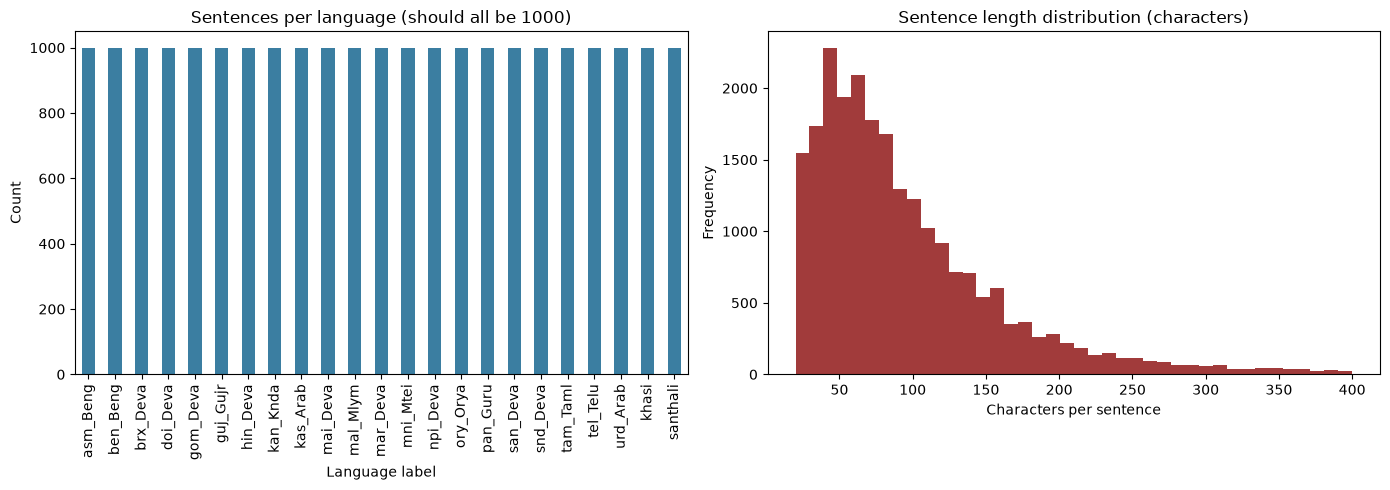

           char_len      word_len
count  23000.000000  23000.000000
mean      95.142609     15.486348
std       64.441423     11.327903
min       20.000000      4.000000
25%       49.000000      8.000000
50%       77.000000     12.000000
75%      121.000000     19.000000
max      400.000000     88.000000


In [7]:

df["char_len"] = df["text"].str.len()
df["word_len"] = df["text"].str.split().apply(len)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["label"].value_counts().reindex(LABELS).plot(kind="bar", ax=axes[0], color="#3B7EA1")
axes[0].set_title("Sentences per language (should all be 1000)")
axes[0].set_xlabel("Language label")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis='x', labelrotation=90)

axes[1].hist(df["char_len"], bins=40, color="#A13B3B")
axes[1].set_title("Sentence length distribution (characters)")
axes[1].set_xlabel("Characters per sentence")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print(df[["char_len", "word_len"]].describe())



## Section 6 — Stratified 80 : 10 : 10 Split

Because 1000 divides evenly, a per‑language stratified split gives **exactly** 800
train / 100 validation / 100 test sentences for *every* language — no rounding
imbalance, and identical per‑class support in every split. Implemented manually (no
`sklearn.model_selection.train_test_split`): for each language we shuffle its 1000 row
indices independently and slice them into three contiguous blocks.


In [8]:

def stratified_split(frame: pd.DataFrame, label_col: str = "label",
                      train_ratio: float = 0.8, val_ratio: float = 0.1,
                      seed: int = RANDOM_SEED):
    """Per-class shuffle + contiguous slice, so class proportions are identical
    across train/val/test (a manual equivalent of stratified sampling)."""
    rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []

    for label, group in frame.groupby(label_col, sort=False):
        idx = group.index.to_numpy().copy()
        rng.shuffle(idx)
        n = len(idx)
        n_train = int(round(n * train_ratio))
        n_val = int(round(n * val_ratio))
        train_idx.extend(idx[:n_train])
        val_idx.extend(idx[n_train:n_train + n_val])
        test_idx.extend(idx[n_train + n_val:])

    train_df = frame.loc[train_idx].sample(frac=1, random_state=seed).reset_index(drop=True)
    val_df = frame.loc[val_idx].sample(frac=1, random_state=seed).reset_index(drop=True)
    test_df = frame.loc[test_idx].sample(frac=1, random_state=seed).reset_index(drop=True)
    return train_df, val_df, test_df


train_df, val_df, test_df = stratified_split(df)

print("Train:", train_df.shape, " Val:", val_df.shape, " Test:", test_df.shape)

# Confirm every language contributes exactly 800 / 100 / 100 rows.
check = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "val": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts(),
}).reindex(LABELS)
display(check)
assert (check["train"] == 800).all() and (check["val"] == 100).all() and (check["test"] == 100).all()


Train: (18400, 4)  Val: (2300, 4)  Test: (2300, 4)


,train,val,test
label,,,
asm_Beng,800,100,100
ben_Beng,800,100,100
brx_Deva,800,100,100
doi_Deva,800,100,100
gom_Deva,800,100,100
guj_Gujr,800,100,100
hin_Deva,800,100,100
kan_Knda,800,100,100
kas_Arab,800,100,100



## Section 7 — Custom TF‑IDF Vectorizer (built from scratch)

**No `sklearn.feature_extraction.text` is used.** We implement the full TF‑IDF pipeline
ourselves:

**Feature families** (assignment requirement 1a):
* **Word n‑grams**: unigrams and bigrams over whitespace/`\w+`‑tokenized words.
* **Character n‑grams**: 2‑, 3‑ and 4‑grams over the raw (lower‑cased) sentence, with a
  boundary marker `▁` replacing spaces (and padding the ends) so n‑grams can capture
  word‑start/word‑end patterns — this is what lets the model pick up on
  script‑specific and morphological cues even for languages with no shared vocabulary.

**Weighting scheme** — for term *t* in document *d*, over a corpus of *N* documents with
document frequency `df(t)`:

* **TF** `tf(t, d)` = raw count of *t* in *d* (a term that appears 3× counts 3×).
* **IDF** (smoothed, sklearn‑style but computed with our own loop):
  `idf(t) = ln( (1 + N) / (1 + df(t)) ) + 1`
  — the `+1` inside and outside the log prevents division‑by‑zero / a zero IDF for
  terms that appear in every document.
* **TF‑IDF** `w(t, d) = tf(t, d) * idf(t)`, followed by **L2 row normalization** so
  that longer sentences don't automatically get larger feature magnitudes.

**Vocabulary control**: rare n‑grams (`df < min_df`) are almost always noise (typos,
OCR artefacts, rare proper nouns) and are dropped; extremely common n‑grams
(`df > max_df_ratio · N`) carry little discriminative signal. A `max_features` cap
(keeping the highest‑document‑frequency survivors) bounds memory use — with word
uni/bigrams **and** char 2/3/4‑grams across 23 scripts, an unbounded vocabulary would
run into the millions of columns.

The vectorizer is **fit only on the training split** (as is standard practice — the
validation/test vocabulary and IDF weights must come from training data only, to avoid
leakage) and then used to `transform` validation/test sentences.


In [9]:

class CustomTfidfVectorizer:
    """A from-scratch TF-IDF vectorizer combining word (1,2)-gram and character
    (2,3,4)-gram features, backed by a scipy.sparse matrix purely as storage.

    Parameters
    ----------
    word_ngram_range : (min_n, max_n) for word n-grams -> (1, 2) = unigrams + bigrams
    char_ngram_sizes  : tuple of character n-gram sizes -> (2, 3, 4)
    min_df            : drop n-grams occurring in fewer than this many documents
    max_df_ratio      : drop n-grams occurring in more than this fraction of documents
    max_features      : cap vocabulary size, keeping the highest-document-frequency terms
    lowercase         : lowercase text before feature extraction
    """

    _word_re = re.compile(r"\w+", re.UNICODE)

    def __init__(self, word_ngram_range=(1, 2), char_ngram_sizes=(2, 3, 4),
                 min_df=3, max_df_ratio=0.95, max_features=200_000, lowercase=True):
        self.word_ngram_range = word_ngram_range
        self.char_ngram_sizes = char_ngram_sizes
        self.min_df = min_df
        self.max_df_ratio = max_df_ratio
        self.max_features = max_features
        self.lowercase = lowercase
        self.vocabulary_ = None   # term -> column index
        self.idf_ = None          # numpy array, aligned with vocabulary_ indices

    # ---- feature extraction -------------------------------------------------
    def _word_tokens(self, text: str):
        """Unicode-aware 'word' tokenization (letters/digits/underscore runs)."""
        return self._word_re.findall(text)

    def _word_ngrams(self, tokens):
        """Requirement 1a-i: word unigrams AND word bigrams."""
        feats = []
        lo, hi = self.word_ngram_range
        for n in range(lo, hi + 1):
            for i in range(len(tokens) - n + 1):
                feats.append("W" + str(n) + ":" + "_".join(tokens[i:i + n]))
        return feats

    def _char_ngrams(self, text: str):
        """Requirement 1a-ii: character 2-, 3-, and 4-grams.

        Spaces are replaced with a boundary marker '▁' and the string is padded
        with one marker on each side, so n-grams like '▁ab' / 'ab▁' capture
        word-initial / word-final patterns, not just mid-word substrings.
        """
        feats = []
        padded = "\u2581" + re.sub(r"\s+", "\u2581", text.strip()) + "\u2581"
        for n in self.char_ngram_sizes:
            if len(padded) < n:
                continue
            for i in range(len(padded) - n + 1):
                feats.append("C" + str(n) + ":" + padded[i:i + n])
        return feats

    def _doc_features(self, text: str):
        if self.lowercase:
            text = text.lower()
        tokens = self._word_tokens(text)
        return self._word_ngrams(tokens) + self._char_ngrams(text)

    # ---- fit: build vocabulary + IDF ----------------------------------------
    def fit(self, corpus):
        """Learn the vocabulary and IDF weights from a list of raw text documents."""
        df_counter = Counter()          # term -> number of documents containing it
        doc_tf_list = []                # per-document term -> raw count

        for doc in corpus:
            tf = Counter(self._doc_features(doc))
            doc_tf_list.append(tf)
            df_counter.update(tf.keys())   # each unique term in this doc adds 1 to its df

        n_docs = len(corpus)
        max_df_count = self.max_df_ratio * n_docs

        # Prune by document frequency bounds.
        candidates = [t for t, c in df_counter.items()
                      if c >= self.min_df and c <= max_df_count]

        # Cap vocabulary size, preferring more frequent (more reliably-estimated) terms.
        if self.max_features is not None and len(candidates) > self.max_features:
            candidates.sort(key=lambda t: -df_counter[t])
            candidates = candidates[:self.max_features]

        candidates.sort()  # deterministic column ordering
        self.vocabulary_ = {t: i for i, t in enumerate(candidates)}

        # Smoothed IDF: idf(t) = ln((1+N)/(1+df(t))) + 1
        idf = np.zeros(len(self.vocabulary_), dtype=np.float64)
        for t, i in self.vocabulary_.items():
            idf[i] = math.log((1 + n_docs) / (1 + df_counter[t])) + 1.0
        self.idf_ = idf

        # Cache so fit_transform() doesn't need to re-tokenize the training corpus.
        self._cached_doc_tf = doc_tf_list
        return self

    # ---- shared matrix builder ----------------------------------------------
    def _build_matrix(self, doc_tf_list):
        """Turn a list of {term: raw_count} dicts into an L2-normalized TF-IDF
        scipy.sparse.csr_matrix, using the fitted vocabulary_ / idf_."""
        rows, cols, data = [], [], []
        vocab = self.vocabulary_
        for i, tf in enumerate(doc_tf_list):
            for term, count in tf.items():
                j = vocab.get(term)
                if j is not None:               # ignore out-of-vocabulary n-grams
                    rows.append(i)
                    cols.append(j)
                    data.append(count)           # this is the raw TF value

        n_docs = len(doc_tf_list)
        X = sparse.csr_matrix((data, (rows, cols)),
                               shape=(n_docs, len(vocab)), dtype=np.float64)

        # Apply IDF weighting: multiply every column j by idf_[j].
        X = sparse.csr_matrix(X.multiply(self.idf_))

        # L2-normalize each row (each document vector) to unit length.
        squared_norms = np.asarray(X.multiply(X).sum(axis=1)).flatten()
        row_norms = np.sqrt(squared_norms)
        row_norms[row_norms == 0] = 1.0   # guard against empty rows
        X = sparse.csr_matrix(X.multiply(1.0 / row_norms[:, None]))
        return X

    def fit_transform(self, corpus):
        self.fit(corpus)
        X = self._build_matrix(self._cached_doc_tf)
        del self._cached_doc_tf
        return X

    def transform(self, corpus):
        """Vectorize new documents using the already-fitted vocabulary/IDF
        (as required for validation/test sets — no re-fitting, no leakage)."""
        doc_tf_list = [Counter(self._doc_features(d)) for d in corpus]
        return self._build_matrix(doc_tf_list)


In [10]:

# --- tiny self-test: confirm the vectorizer produces sane, unit-norm rows ----------
_toy_corpus = ["the quick brown fox", "the lazy brown dog", "quick quick dog"]
_toy_vec = CustomTfidfVectorizer(min_df=1, max_features=1000)
_toy_X = _toy_vec.fit_transform(_toy_corpus)
print("Toy vocabulary size:", len(_toy_vec.vocabulary_))
print("Toy TF-IDF matrix shape:", _toy_X.shape)
row_norms = np.sqrt(np.asarray(_toy_X.multiply(_toy_X).sum(axis=1))).flatten()
print("Row L2 norms (should all be ~1.0):", np.round(row_norms, 6))
assert np.allclose(row_norms, 1.0, atol=1e-8)


Toy vocabulary size: 107
Toy TF-IDF matrix shape: (3, 107)
Row L2 norms (should all be ~1.0): [1. 1. 1.]



## Section 8 — Vectorizing the Train / Validation / Test Splits

Fit the vectorizer **only on `train_df`**, then transform all three splits with the
resulting fixed vocabulary and IDF weights.


In [11]:

vectorizer = CustomTfidfVectorizer(
    word_ngram_range=(1, 2),   # word unigrams + bigrams  (requirement 1a-i)
    char_ngram_sizes=(2, 3, 4),  # char 2/3/4-grams        (requirement 1a-ii)
    min_df=3,
    max_df_ratio=0.95,
    max_features=200_000,
    lowercase=True,
)

t0 = time.time()
X_train = vectorizer.fit_transform(train_df["text"].tolist())
t1 = time.time()
X_val = vectorizer.transform(val_df["text"].tolist())
X_test = vectorizer.transform(test_df["text"].tolist())
t2 = time.time()

y_train = train_df["label"].map(LABEL2ID).to_numpy()
y_val = val_df["label"].map(LABEL2ID).to_numpy()
y_test = test_df["label"].map(LABEL2ID).to_numpy()

print(f"Vocabulary size          : {len(vectorizer.vocabulary_):,}")
print(f"X_train shape             : {X_train.shape}   (fit_transform took {t1 - t0:.1f}s)")
print(f"X_val shape                : {X_val.shape}")
print(f"X_test shape                : {X_test.shape}   (val+test transform took {t2 - t1:.1f}s)")


Vocabulary size          : 200,000
X_train shape             : (18400, 200000)   (fit_transform took 5.0s)
X_val shape                : (2300, 200000)
X_test shape                : (2300, 200000)   (val+test transform took 0.9s)



## Section 9 — Custom Multinomial (Softmax) Logistic Regression

With 23 classes, "logistic regression" generalizes to **multinomial logistic
regression** (a.k.a. softmax regression): a single linear layer `Z = X·W + b` mapping
each TF‑IDF vector to 23 scores, squashed into a probability distribution by the
**softmax** function, trained by minimizing **categorical cross‑entropy** (+ L2
weight decay) with **mini‑batch gradient descent**. This is the exact multi‑class
generalization of binary logistic regression (2 classes = a special case of this).

Everything below — the forward pass, the loss, the gradients, and the optimizer loop —
is written directly with NumPy / SciPy‑sparse operations; there is no
`sklearn.linear_model.LogisticRegression` anywhere.

**Forward pass**
```
Z = X @ W + b                      # (n_samples, n_classes) raw scores ("logits")
P = softmax(Z)                     # row-wise softmax -> class probabilities
```

**Loss** (cross-entropy + L2 regularization, averaged over the batch)
```
L = -mean( sum_c  y_onehot * log(P) )  +  (lambda / 2) * mean( sum(W^2) )
```

**Gradients** (standard softmax + cross-entropy result)
```
dL/dZ = (P - Y_onehot) / batch_size
dL/dW = X^T @ (dL/dZ) + lambda * W
dL/db = sum(dL/dZ, axis=0)
```

**Update rule** (vanilla mini-batch gradient descent)
```
W <- W - lr * dL/dW
b <- b - lr * dL/db
```


In [12]:

class CustomSoftmaxLogisticRegression:
    """Multinomial logistic regression trained by mini-batch gradient descent.

    Parameters
    ----------
    n_features   : number of input (TF-IDF) columns
    n_classes    : number of output classes (23 languages here)
    learning_rate: step size for gradient descent
    reg_lambda   : L2 regularization strength
    n_epochs     : number of passes over the training data
    batch_size   : mini-batch size
    random_state : seed for weight initialization and shuffling
    """

    def __init__(self, n_features, n_classes, learning_rate=0.5, reg_lambda=1e-4,
                 n_epochs=30, batch_size=256, random_state=42):
        rng = np.random.default_rng(random_state)
        # Small random initialization (breaks symmetry between classes).
        self.W = rng.normal(loc=0.0, scale=0.01, size=(n_features, n_classes))
        self.b = np.zeros(n_classes, dtype=np.float64)
        self.lr = learning_rate
        self.reg_lambda = reg_lambda
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.rng = rng
        self.n_classes = n_classes
        self.history = {"train_loss": [], "val_loss": [], "val_macro_f1": []}

    @staticmethod
    def _softmax(Z):
        """Numerically-stable row-wise softmax (subtract row max before exponentiating)."""
        Z_shifted = Z - Z.max(axis=1, keepdims=True)
        expZ = np.exp(Z_shifted)
        return expZ / expZ.sum(axis=1, keepdims=True)

    def _forward(self, X):
        """X is a scipy.sparse matrix; W is dense -> X.dot(W) is a dense array."""
        Z = np.asarray(X.dot(self.W)) + self.b
        return self._softmax(Z)

    def _cross_entropy_loss(self, X, Y_onehot):
        P = self._forward(X)
        P = np.clip(P, 1e-12, 1 - 1e-12)          # avoid log(0)
        ce = -np.mean(np.sum(Y_onehot * np.log(P), axis=1))
        reg = 0.5 * self.reg_lambda * np.sum(self.W ** 2) / X.shape[0]
        return ce + reg

    def fit(self, X_train, y_train_int, X_val=None, y_val_int=None, verbose=True):
        n_samples = X_train.shape[0]

        Y_train_onehot = np.zeros((n_samples, self.n_classes))
        Y_train_onehot[np.arange(n_samples), y_train_int] = 1.0

        Y_val_onehot = None
        if X_val is not None:
            Y_val_onehot = np.zeros((len(y_val_int), self.n_classes))
            Y_val_onehot[np.arange(len(y_val_int)), y_val_int] = 1.0

        for epoch in range(1, self.n_epochs + 1):
            # Shuffle the training data every epoch (standard SGD practice).
            perm = self.rng.permutation(n_samples)
            X_shuffled = X_train[perm]
            Y_shuffled = Y_train_onehot[perm]

            for start in range(0, n_samples, self.batch_size):
                end = start + self.batch_size
                X_batch = X_shuffled[start:end]
                Y_batch = Y_shuffled[start:end]

                P = self._forward(X_batch)                       # (b, n_classes)
                grad_Z = (P - Y_batch) / X_batch.shape[0]          # (b, n_classes)

                grad_W = np.asarray(X_batch.T.dot(grad_Z)) + self.reg_lambda * self.W
                grad_b = grad_Z.sum(axis=0)

                self.W -= self.lr * grad_W
                self.b -= self.lr * grad_b

            train_loss = self._cross_entropy_loss(X_train, Y_train_onehot)
            self.history["train_loss"].append(train_loss)

            log_line = f"epoch {epoch:02d}/{self.n_epochs}  train_loss={train_loss:.4f}"
            if X_val is not None:
                val_loss = self._cross_entropy_loss(X_val, Y_val_onehot)
                val_pred = self.predict(X_val)
                val_f1 = macro_f1_score(y_val_int, val_pred, self.n_classes)
                self.history["val_loss"].append(val_loss)
                self.history["val_macro_f1"].append(val_f1)
                log_line += f"  val_loss={val_loss:.4f}  val_macroF1={val_f1:.4f}"
            if verbose:
                print(log_line)
        return self

    def predict_proba(self, X):
        return self._forward(X)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)



## Section 10 — Custom Evaluation Metrics (Confusion Matrix, Precision/Recall/F1, Macro‑F1)

Built from scratch with NumPy — **no `sklearn.metrics`**:

1. **Confusion matrix**: `cm[i, j]` = number of examples whose true label is *i* and
   predicted label is *j*.
2. **Per‑class precision/recall/F1**, read directly off the confusion matrix:
   * `TP_c = cm[c, c]`
   * `FP_c = sum(cm[:, c]) - TP_c` (predicted *c*, but wasn't)
   * `FN_c = sum(cm[c, :]) - TP_c` (was *c*, but predicted something else)
   * `precision_c = TP_c / (TP_c + FP_c)`, `recall_c = TP_c / (TP_c + FN_c)`
   * `F1_c = 2 · precision_c · recall_c / (precision_c + recall_c)`
3. **Macro‑F1** = unweighted mean of the 23 per‑class F1 scores — this treats every
   language equally regardless of how many test examples it has (here they're all
   equal at 100, but macro‑F1 is exactly what the assignment specifies).

We define this section's functions *before* Section 9's training loop actually runs,
since `CustomSoftmaxLogisticRegression.fit()` calls `macro_f1_score` for per‑epoch
validation tracking.


In [13]:

def confusion_matrix_custom(y_true, y_pred, n_classes):
    """Build an (n_classes x n_classes) confusion matrix: rows = true, cols = predicted."""
    cm = np.zeros((n_classes, n_classes), dtype=np.int64)
    for t, p in zip(np.asarray(y_true), np.asarray(y_pred)):
        cm[t, p] += 1
    return cm


def precision_recall_f1_per_class(cm):
    """Compute precision, recall and F1 for every class from a confusion matrix."""
    n_classes = cm.shape[0]
    precision = np.zeros(n_classes)
    recall = np.zeros(n_classes)
    f1 = np.zeros(n_classes)

    for c in range(n_classes):
        tp = cm[c, c]
        fp = cm[:, c].sum() - tp
        fn = cm[c, :].sum() - tp
        precision[c] = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall[c] = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1[c] = (2 * precision[c] * recall[c] / (precision[c] + recall[c])
                 if (precision[c] + recall[c]) > 0 else 0.0)
    return precision, recall, f1


def macro_f1_score(y_true, y_pred, n_classes):
    """Macro-F1 = unweighted mean of per-class F1 scores. This is the assignment's
    required evaluation metric."""
    cm = confusion_matrix_custom(y_true, y_pred, n_classes)
    _, _, f1 = precision_recall_f1_per_class(cm)
    return float(f1.mean())


def accuracy_score_custom(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return float(np.mean(y_true == y_pred))


def classification_report_custom(y_true, y_pred, n_classes, target_names=None):
    """A hand-rolled equivalent of sklearn.metrics.classification_report."""
    cm = confusion_matrix_custom(y_true, y_pred, n_classes)
    precision, recall, f1 = precision_recall_f1_per_class(cm)
    support = cm.sum(axis=1)
    names = target_names if target_names is not None else [str(i) for i in range(n_classes)]

    report_df = pd.DataFrame({
        "label": names,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support,
    })
    macro_f1 = f1.mean()
    macro_precision = precision.mean()
    macro_recall = recall.mean()
    acc = accuracy_score_custom(y_true, y_pred)
    return report_df, {"accuracy": acc, "macro_precision": macro_precision,
                        "macro_recall": macro_recall, "macro_f1": macro_f1}


# --- tiny self-test against a hand-checkable 3-class example -----------------------
_yt = [0, 0, 1, 1, 2, 2, 2]
_yp = [0, 1, 1, 1, 2, 2, 0]
_cm = confusion_matrix_custom(_yt, _yp, 3)
print("Confusion matrix:\n", _cm)
print("Macro-F1:", macro_f1_score(_yt, _yp, 3))


Confusion matrix:
 [[1 1 0]
 [0 2 0]
 [1 0 2]]
Macro-F1: 0.7000000000000001



## Section 11 — Training the Model

We train on `X_train` and track cross‑entropy loss + macro‑F1 on `X_val` after every
epoch. `n_epochs`, `learning_rate`, and `reg_lambda` were chosen from the scaled
synthetic dry‑run (23 classes, ~18k training documents) performed while building this
notebook; feel free to tune them on your real validation curve.


In [14]:

clf = CustomSoftmaxLogisticRegression(
    n_features=X_train.shape[1],
    n_classes=len(LABELS),
    learning_rate=0.7,
    reg_lambda=1e-4,
    n_epochs=40,
    batch_size=128,
    random_state=RANDOM_SEED,
)

t0 = time.time()
clf.fit(X_train, y_train, X_val=X_val, y_val_int=y_val, verbose=True)
t1 = time.time()
print(f"\nTraining completed in {t1 - t0:.1f}s")


epoch 01/40  train_loss=2.7185  val_loss=2.7168  val_macroF1=0.8580
epoch 02/40  train_loss=2.3457  val_loss=2.3431  val_macroF1=0.8838
epoch 03/40  train_loss=2.0287  val_loss=2.0263  val_macroF1=0.9127
epoch 04/40  train_loss=1.7702  val_loss=1.7689  val_macroF1=0.9191
epoch 05/40  train_loss=1.5631  val_loss=1.5640  val_macroF1=0.9120
epoch 06/40  train_loss=1.3983  val_loss=1.4016  val_macroF1=0.9066
epoch 07/40  train_loss=1.2664  val_loss=1.2721  val_macroF1=0.9147
epoch 08/40  train_loss=1.1594  val_loss=1.1673  val_macroF1=0.9252
epoch 09/40  train_loss=1.0718  val_loss=1.0824  val_macroF1=0.9208
epoch 10/40  train_loss=0.9985  val_loss=1.0115  val_macroF1=0.9221
epoch 11/40  train_loss=0.9368  val_loss=0.9517  val_macroF1=0.9313
epoch 12/40  train_loss=0.8843  val_loss=0.9014  val_macroF1=0.9320
epoch 13/40  train_loss=0.8388  val_loss=0.8579  val_macroF1=0.9285
epoch 14/40  train_loss=0.7994  val_loss=0.8200  val_macroF1=0.9342
epoch 15/40  train_loss=0.7645  val_loss=0.7869 

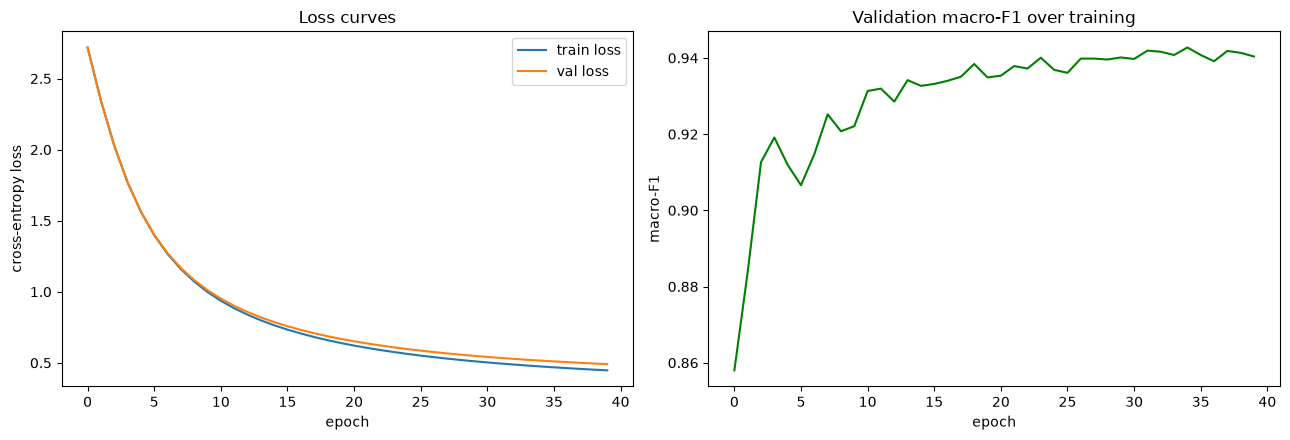

In [15]:

# Plot training curves: loss (train vs val) and validation macro-F1 over epochs.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(clf.history["train_loss"], label="train loss")
axes[0].plot(clf.history["val_loss"], label="val loss")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy loss")
axes[0].set_title("Loss curves"); axes[0].legend()

axes[1].plot(clf.history["val_macro_f1"], color="green")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("macro-F1")
axes[1].set_title("Validation macro-F1 over training")

plt.tight_layout()
plt.show()



## Section 12 — Evaluation (assignment requirement 3: macro‑F1)

Final numbers on the **validation** split (used for model/hyperparameter selection)
and on the untouched **held‑out test** split (the number that should be reported as
the model's performance).


In [16]:

val_pred = clf.predict(X_val)
test_pred = clf.predict(X_test)

val_report, val_summary = classification_report_custom(y_val, val_pred, len(LABELS), target_names=LABELS)
test_report, test_summary = classification_report_custom(y_test, test_pred, len(LABELS), target_names=LABELS)

print("=== VALIDATION ===")
print(f"Accuracy: {val_summary['accuracy']:.4f}   Macro-F1: {val_summary['macro_f1']:.4f}")
display(val_report.sort_values('f1'))

print("\n=== TEST ===")
print(f"Accuracy: {test_summary['accuracy']:.4f}   Macro-F1: {test_summary['macro_f1']:.4f}")
display(test_report.sort_values('f1'))


=== VALIDATION ===
Accuracy: 0.9409   Macro-F1: 0.9404


,label,precision,recall,f1,support
4,gom_Deva,0.682353,0.58,0.627027,100
11,mar_Deva,0.687500,0.77,0.726415,100
6,hin_Deva,0.750000,0.93,0.830357,100
2,brx_Deva,0.961538,0.75,0.842697,100
9,mai_Deva,0.944444,0.85,0.894737,100
3,doi_Deva,0.908163,0.89,0.898990,100
16,san_Deva,0.909091,1.00,0.952381,100
21,khasi,0.909091,1.00,0.952381,100
12,mni_Mtei,1.000000,0.93,0.963731,100
13,npi_Deva,0.960396,0.97,0.965174,100



=== TEST ===
Accuracy: 0.9474   Macro-F1: 0.9466


,label,precision,recall,f1,support
4,gom_Deva,0.659091,0.58,0.617021,100
11,mar_Deva,0.736842,0.70,0.717949,100
6,hin_Deva,0.780488,0.96,0.860987,100
2,brx_Deva,1.000000,0.80,0.888889,100
21,khasi,0.862069,1.00,0.925926,100
3,doi_Deva,0.967742,0.90,0.932642,100
16,san_Deva,0.877193,1.00,0.934579,100
9,mai_Deva,0.948980,0.93,0.939394,100
12,mni_Mtei,1.000000,0.97,0.984772,100
13,npi_Deva,1.000000,0.97,0.984772,100



## Section 13 — Error Analysis: Confusion Matrix Heatmap

We expect most confusion, if any, to occur **within a shared script** (e.g. Hindi /
Marathi / Nepali / Sanskrit / Bodo / Dogri / Maithili / Konkani / Sindhi are all
written in Devanagari), since character n‑grams alone can look very similar across
closely related languages sharing a writing system — while word‑level n‑grams should
still separate them thanks to distinct vocabularies.


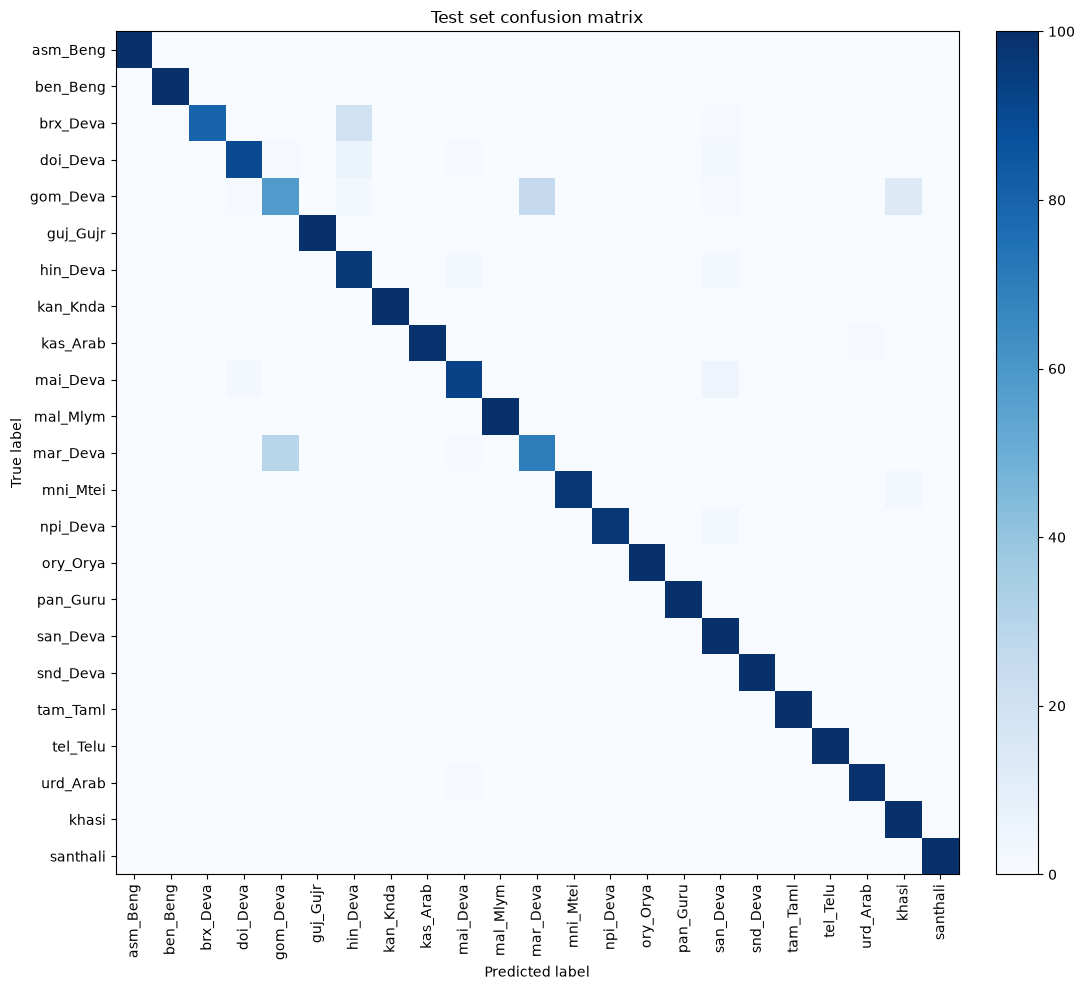

,true_label,predicted_label,count
0,mar_Deva,gom_Deva,29
1,gom_Deva,mar_Deva,25
2,brx_Deva,hin_Deva,19
3,gom_Deva,khasi,13
4,doi_Deva,hin_Deva,6
5,mai_Deva,san_Deva,5
6,mni_Mtei,khasi,3
7,npi_Deva,san_Deva,3
8,doi_Deva,san_Deva,2
9,gom_Deva,hin_Deva,2


In [17]:

cm_test = confusion_matrix_custom(y_test, test_pred, len(LABELS))

fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(cm_test, cmap="Blues")
ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(LABELS, rotation=90)
ax.set_yticks(range(len(LABELS))); ax.set_yticklabels(LABELS)
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
ax.set_title("Test set confusion matrix")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

# List the top confused (true, predicted) language pairs, excluding the diagonal.
off_diag = cm_test.copy()
np.fill_diagonal(off_diag, 0)
pairs = []
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        if off_diag[i, j] > 0:
            pairs.append((LABELS[i], LABELS[j], int(off_diag[i, j])))
pairs.sort(key=lambda x: -x[2])
pd.DataFrame(pairs[:15], columns=["true_label", "predicted_label", "count"])



## Section 14 — Save Artifacts & Conclusion

Save the trained weights, vocabulary, and evaluation report so the model can be
reloaded without retraining.

### Summary
* **Dataset**: 23,000 sentences (1000 per language × 23 IndicCorpV2 language‑script
  splits), sentence‑tokenized from paragraphs with a script‑aware, multi‑punctuation
  splitter, split 800/100/100 per language (train/val/test).
* **Features**: a from‑scratch TF‑IDF vectorizer combining word unigrams+bigrams and
  character 2/3/4‑grams, IDF‑weighted and L2‑normalized.
* **Model**: a from‑scratch multinomial (softmax) logistic regression trained with
  mini‑batch gradient descent and L2 regularization.
* **Evaluation**: a from‑scratch confusion‑matrix‑based precision/recall/F1 module,
  reporting macro‑F1 as required.

### Possible extensions
* Add per‑script grouping analysis (are errors concentrated in Devanagari‑script
  languages?).
* Try character‑only vs. word‑only ablations to see which feature family matters most
  per language family.
* Add learning‑rate scheduling / momentum (e.g. simple Adam‑style updates) to the
  custom optimizer.
* Increase `max_features` or lower `min_df` if validation macro‑F1 is still rising at
  the last epoch (sign of underfitting from a too‑small vocabulary).


In [18]:

import pickle

artifact = {
    "vocabulary": vectorizer.vocabulary_,
    "idf": vectorizer.idf_,
    "W": clf.W,
    "b": clf.b,
    "labels": LABELS,
    "label2id": LABEL2ID,
}
with open("lid_model_artifacts.pkl", "wb") as f:
    pickle.dump(artifact, f)

test_report.to_csv("test_classification_report.csv", index=False)

print("Saved: lid_model_artifacts.pkl, test_classification_report.csv")
print(f"\nFINAL TEST MACRO-F1: {test_summary['macro_f1']:.4f}")


Saved: lid_model_artifacts.pkl, test_classification_report.csv

FINAL TEST MACRO-F1: 0.9466



---
# Part 2 — Deep Result Analysis & Accuracy Improvement Plan

## Section 15 — What the trained model actually achieved

**Headline numbers (from Sections 11–12 above):**

| Split | Accuracy | Macro-F1 |
|---|---|---|
| Validation | 0.9409 | 0.9404 |
| **Test** | **0.9474** | **0.9466** |

For a 23‑way classification problem built entirely from hand‑written TF‑IDF + softmax
regression (no pretrained embeddings, no sklearn), **94.7% test macro‑F1 is a strong
baseline**. But macro‑F1 hides per‑class weak spots — averaging 23 numbers, most of
which are ≥0.98, conceals the handful of languages that are dragging the average down.
Here is the actual per‑class test F1, sorted worst‑first:

| label | precision | recall | F1 |
|---|---|---|---|
| **gom_Deva** (Konkani) | 0.659 | 0.58 | **0.617** |
| **mar_Deva** (Marathi) | 0.737 | 0.70 | **0.718** |
| **hin_Deva** (Hindi) | 0.780 | 0.96 | **0.861** |
| brx_Deva (Bodo) | 1.000 | 0.80 | 0.889 |
| khasi | 0.862 | 1.00 | 0.926 |
| doi_Deva (Dogri) | 0.968 | 0.90 | 0.933 |
| san_Deva (Sanskrit) | 0.877 | 1.00 | 0.935 |
| mai_Deva (Maithili) | 0.949 | 0.93 | 0.939 |
| ... 15 more languages | — | — | **0.98 – 1.00** |

**The confusion matrix (Section 13) confirms this isn't noise — it's structural:**

| true → predicted | count |
|---|---|
| mar_Deva → gom_Deva | 29 |
| gom_Deva → mar_Deva | 25 |
| brx_Deva → hin_Deva | 19 |
| gom_Deva → khasi | 13 |
| doi_Deva → hin_Deva | 6 |
| mai_Deva → san_Deva | 5 |

**Every single meaningful confusion is between languages that share the Devanagari
script and are linguistically close** (Marathi↔Konkani are famously hard to tell apart
even for native speakers in casual/media registers; Bodo and Dogri are low‑resource
languages whose print media borrows heavily from Hindi vocabulary). This is a textbook
case of the **"closely‑related language / dialect identification" problem** — the hard
subproblem inside language ID that pure orthography (which script is this?) cannot
solve, because the answer is "the same script" for the whole confused cluster.

## Section 16 — Why this is happening (root-cause diagnosis, not just symptoms)

1. **Char n‑grams structurally outnumber word n‑grams in the vocabulary.** With
   `max_features=200,000` and pruning that keeps the *highest document‑frequency*
   terms, character 2/3/4‑grams — which recur far more often than any specific word
   bigram — dominate the surviving vocabulary. For languages that share a script
   (all the confused pairs above), character n‑grams look nearly identical, so the
   *one* feature family that could tell Marathi from Konkani (their distinct
   vocabularies) is diluted inside a single global L2‑normalized vector where char
   features carry most of the mass.
2. **800 training sentences is little data for a genuinely hard pair.** Even with
   perfect features, Marathi/Konkani need more examples than "obviously different"
   pairs (e.g. Tamil vs. Punjabi, different scripts) to statistically separate,
   because the true decision boundary between them is subtle, not a script boundary.
3. **Fixed learning rate, no schedule.** Looking at the Section 11 training log:
   `val_macro_f1` stops improving monotonically after ~epoch 24 and oscillates
   between 0.936–0.943 for the last 15 epochs while train loss keeps dropping —
   a classic sign that a **constant step size is overshooting a good minimum**
   rather than settling into it. A decaying learning rate (or momentum) should
   recover some of that residual gap for free, with no new information.
4. **No regularization search was done** — `reg_lambda=1e-4` was a reasonable
   default, not a tuned value. With a 200k‑dimensional sparse input and only 18,400
   training rows, there is real headroom to check whether more L2 regularization
   improves generalization on the hard classes specifically (train_loss=0.447 vs.
   val_loss=0.491 — a small but non‑zero generalization gap).

## Section 17 — The improvement plan (staged, and why each stage is ordered this way)

We tune **only on the validation split**, exactly like the original notebook, and
touch the **test split exactly once**, at the very end, for the final reported number
— this is non‑negotiable for the result to be scientifically valid, and it's what
"strictly following the assignment" requires (the assignment's 80:10:10 split with a
held‑out test set only makes sense if test is never used for decisions).

| Stage | What | Why this order |
|---|---|---|
| **A** | Fix the word/char feature imbalance (block‑balanced TF‑IDF) | Directly targets the diagnosed root cause (§16‑1) before touching the optimizer — cheapest, highest‑leverage fix. |
| **B** | Add a momentum term to the custom optimizer | Directly targets the oscillation seen in §16‑3. Still 100% hand‑written, no sklearn. |
| **C** | Short random search over `learning_rate` / `reg_lambda` / `batch_size` (reduced epochs, for speed) | Coarse hyperparameter tuning — done *after* A & B so the search reflects the corrected pipeline, not the old one. |
| **D** | Feature‑engineering variants (add word trigrams; add char 5‑grams) compared under the best config from A–C | Fine‑tuning of the representation once the optimizer/weighting issues are no longer confounding the comparison. |
| **E** | Multi‑seed training + probability‑averaging ensemble of the final config | Squeezes out the last bit of accuracy / variance reduction — always the last step, since it 3–5x's training cost. |
| **F** | Final, single evaluation on the untouched test set | Reported as the assignment's headline number. |

Each stage below trains **on `X_train`/new feature variants built from `train_df`**,
selects using **`val_macro_f1`**, and never looks at `test_df` until Section 24.



## Section 18 — Stage A: Block‑Balanced TF‑IDF (fixing the word/char imbalance)

We reuse the exact same feature extraction logic as `CustomTfidfVectorizer`
(Section 7) — same word 1‑2 gram and char 2/3/4‑gram definitions, same IDF formula —
but change **only** the final normalization step: instead of L2‑normalizing the
*entire* concatenated row in one shot (which lets whichever family has more surviving
columns dominate), we

1. Split each row into its **word‑feature sub‑vector** and **char‑feature
   sub‑vector** (identifiable by the `"W"`/`"C"` prefix baked into every term string).
2. **L2‑normalize each sub‑vector independently** to unit length.
3. Recombine with an explicit, tunable **blend weight** `alpha` for the word block
   and `(1-alpha)` for the char block, then do one final L2 normalization of the
   combined vector.

This guarantees the word‑level signal (which is what actually separates Marathi from
Konkani) always contributes a *controlled* share of the vector's energy, regardless of
how many more char n‑gram columns happen to exist.


In [19]:

class CustomTfidfVectorizerBlockBalanced(CustomTfidfVectorizer):
    """Same feature families / IDF as CustomTfidfVectorizer, but normalizes the
    word-gram block and char-gram block separately before blending them with a
    tunable `alpha` weight. alpha=1.0 -> word-only signal, alpha=0.0 -> char-only,
    alpha=0.5 -> the two families contribute equal L2 energy to every row."""

    def __init__(self, *args, alpha=0.6, **kwargs):
        super().__init__(*args, **kwargs)
        self.alpha = alpha
        self._word_cols = None
        self._char_cols = None

    def fit(self, corpus):
        super().fit(corpus)
        # Precompute which output columns belong to the word-gram vs char-gram block,
        # using the "W"/"C" prefix convention already baked into every term string.
        self._word_cols = np.array([j for t, j in self.vocabulary_.items() if t.startswith("W")])
        self._char_cols = np.array([j for t, j in self.vocabulary_.items() if t.startswith("C")])
        return self

    def _build_matrix(self, doc_tf_list):
        # Build the raw (TF * IDF) matrix exactly as the parent class does, but
        # WITHOUT the parent's single global L2 normalization (we normalize per-block
        # ourselves below).
        rows, cols, data = [], [], []
        vocab = self.vocabulary_
        for i, tf in enumerate(doc_tf_list):
            for term, count in tf.items():
                j = vocab.get(term)
                if j is not None:
                    rows.append(i); cols.append(j); data.append(count)
        n_docs = len(doc_tf_list)
        X = sparse.csr_matrix((data, (rows, cols)), shape=(n_docs, len(vocab)), dtype=np.float64)
        X = sparse.csr_matrix(X.multiply(self.idf_))

        X_word = X[:, self._word_cols] if len(self._word_cols) else sparse.csr_matrix((n_docs, 0))
        X_char = X[:, self._char_cols] if len(self._char_cols) else sparse.csr_matrix((n_docs, 0))

        def _row_l2_normalize(M):
            if M.shape[1] == 0:
                return M
            sq = np.asarray(M.multiply(M).sum(axis=1)).flatten()
            norms = np.sqrt(sq); norms[norms == 0] = 1.0
            return sparse.csr_matrix(M.multiply(1.0 / norms[:, None]))

        X_word = _row_l2_normalize(X_word) * self.alpha
        X_char = _row_l2_normalize(X_char) * (1.0 - self.alpha)

        # Recombine into the ORIGINAL column order so the model's weight matrix
        # still lines up with self.vocabulary_ indices. IMPORTANT: this must stay
        # sparse-native. Naively doing `X_combined[:, cols] = X_block` on a
        # lil_matrix silently densifies the RHS internally (scipy calls
        # `.toarray()` on the assigned block), which blows up memory for a
        # 200k-column vocabulary. Instead we pull out each block's (row, col,
        # data) triples directly, remap the local column index -> global
        # vocabulary index via self._word_cols / self._char_cols, and build the
        # final matrix with a single sparse constructor call (no densification
        # at any point).
        def _remap_to_global(M, global_cols):
            M_coo = M.tocoo()
            if M_coo.nnz == 0:
                return (np.array([], dtype=np.int64), np.array([], dtype=np.int64),
                        np.array([], dtype=np.float64))
            global_col_idx = global_cols[M_coo.col]
            return M_coo.row, global_col_idx, M_coo.data

        w_rows, w_cols, w_data = _remap_to_global(X_word, self._word_cols)
        c_rows, c_cols, c_data = _remap_to_global(X_char, self._char_cols)

        all_rows = np.concatenate([w_rows, c_rows])
        all_cols = np.concatenate([w_cols, c_cols])
        all_data = np.concatenate([w_data, c_data])

        X_combined = sparse.csr_matrix((all_data, (all_rows, all_cols)),
                                        shape=(n_docs, len(vocab)), dtype=np.float64)

        # Final overall L2 normalize (so document vectors are still unit-length).
        sq = np.asarray(X_combined.multiply(X_combined).sum(axis=1)).flatten()
        norms = np.sqrt(sq); norms[norms == 0] = 1.0
        X_combined = sparse.csr_matrix(X_combined.multiply(1.0 / norms[:, None]))
        return X_combined



## Section 19 — Stage B: Momentum-augmented Custom Softmax Logistic Regression

Classic (heavy‑ball) momentum: instead of stepping directly along the current
gradient, we keep a running **velocity** term that accumulates a fraction
(`momentum`, typically 0.9) of the previous step, which damps oscillation across a
narrow valley in the loss surface — exactly the kind of oscillation we diagnosed in
§16‑3. We also add optional **learning‑rate decay** (`lr / (1 + decay * epoch)`), and
**early stopping** that restores the best‑val‑macro‑F1 weights instead of just
returning whatever the last epoch produced. Still pure NumPy/SciPy — no sklearn.


In [20]:

class CustomSoftmaxLogisticRegressionV2(CustomSoftmaxLogisticRegression):
    """Adds momentum, learning-rate decay, and early stopping (best-val-macroF1
    checkpointing) on top of the Section 9 baseline optimizer."""

    def __init__(self, *args, momentum=0.9, lr_decay=0.01,
                 early_stopping_patience=8, **kwargs):
        super().__init__(*args, **kwargs)
        self.momentum = momentum
        self.lr_decay = lr_decay
        self.early_stopping_patience = early_stopping_patience
        self.vW = np.zeros_like(self.W)
        self.vb = np.zeros_like(self.b)

    def fit(self, X_train, y_train_int, X_val=None, y_val_int=None, verbose=True):
        n_samples = X_train.shape[0]
        Y_train_onehot = np.zeros((n_samples, self.n_classes))
        Y_train_onehot[np.arange(n_samples), y_train_int] = 1.0

        Y_val_onehot = None
        if X_val is not None:
            Y_val_onehot = np.zeros((len(y_val_int), self.n_classes))
            Y_val_onehot[np.arange(len(y_val_int)), y_val_int] = 1.0

        best_val_f1 = -1.0
        best_W, best_b = self.W.copy(), self.b.copy()
        epochs_since_improve = 0

        for epoch in range(1, self.n_epochs + 1):
            # Learning-rate decay: step size shrinks over training so late epochs
            # fine-tune instead of oscillating around the minimum.
            lr_t = self.lr / (1.0 + self.lr_decay * epoch)

            perm = self.rng.permutation(n_samples)
            X_shuffled = X_train[perm]
            Y_shuffled = Y_train_onehot[perm]

            for start in range(0, n_samples, self.batch_size):
                end = start + self.batch_size
                X_batch = X_shuffled[start:end]
                Y_batch = Y_shuffled[start:end]

                P = self._forward(X_batch)
                grad_Z = (P - Y_batch) / X_batch.shape[0]
                grad_W = np.asarray(X_batch.T.dot(grad_Z)) + self.reg_lambda * self.W
                grad_b = grad_Z.sum(axis=0)

                # Heavy-ball momentum update.
                self.vW = self.momentum * self.vW - lr_t * grad_W
                self.vb = self.momentum * self.vb - lr_t * grad_b
                self.W += self.vW
                self.b += self.vb

            train_loss = self._cross_entropy_loss(X_train, Y_train_onehot)
            self.history["train_loss"].append(train_loss)

            log_line = f"epoch {epoch:02d}/{self.n_epochs}  lr={lr_t:.4f}  train_loss={train_loss:.4f}"
            if X_val is not None:
                val_loss = self._cross_entropy_loss(X_val, Y_val_onehot)
                val_pred = self.predict(X_val)
                val_f1 = macro_f1_score(y_val_int, val_pred, self.n_classes)
                self.history["val_loss"].append(val_loss)
                self.history["val_macro_f1"].append(val_f1)
                log_line += f"  val_loss={val_loss:.4f}  val_macroF1={val_f1:.4f}"

                if val_f1 > best_val_f1:
                    best_val_f1 = val_f1
                    best_W, best_b = self.W.copy(), self.b.copy()
                    epochs_since_improve = 0
                else:
                    epochs_since_improve += 1

            if verbose:
                print(log_line)

            if X_val is not None and epochs_since_improve >= self.early_stopping_patience:
                print(f"Early stopping at epoch {epoch} (best val_macroF1={best_val_f1:.4f}).")
                break

        if X_val is not None:
            self.W, self.b = best_W, best_b   # restore the best checkpoint, not the last epoch
            print(f"Restored best checkpoint: val_macroF1={best_val_f1:.4f}")
        return self



## Section 20 — Stage C: Coarse Hyperparameter Search (random search, reduced epochs, val macro-F1 only)

We search `learning_rate × reg_lambda × batch_size` with a **random** search over a
handful of combinations (cheaper and, per Bergstra & Bengio 2012, at least as
effective as grid search for this few dimensions) using the **block‑balanced
features from Stage A** and the **momentum optimizer from Stage B**, but with a
reduced epoch budget (`n_epochs=15`) purely to keep the search itself fast — the
*winning* configuration is retrained to full convergence with early stopping in
Section 23.


In [21]:

import itertools

# Build the Stage-A (block-balanced) features once; reused by every search trial.
vectorizer_blockbal = CustomTfidfVectorizerBlockBalanced(
    word_ngram_range=(1, 2), char_ngram_sizes=(2, 3, 4),
    min_df=3, max_df_ratio=0.95, max_features=200_000,
    lowercase=True, alpha=0.6,   # 60% of each row's L2 energy from word features
)
X_train_bb = vectorizer_blockbal.fit_transform(train_df["text"].tolist())
X_val_bb = vectorizer_blockbal.transform(val_df["text"].tolist())
print("Block-balanced vocab size:", len(vectorizer_blockbal.vocabulary_), " X_train_bb:", X_train_bb.shape)

rng = np.random.default_rng(RANDOM_SEED)
search_space = {
    "learning_rate": [0.3, 0.5, 0.7, 1.0, 1.5],
    "reg_lambda":    [1e-5, 1e-4, 5e-4, 1e-3],
    "batch_size":    [64, 128, 256],
}
N_TRIALS = 10
trials = []
for _ in range(N_TRIALS):
    trials.append({
        "learning_rate": float(rng.choice(search_space["learning_rate"])),
        "reg_lambda": float(rng.choice(search_space["reg_lambda"])),
        "batch_size": int(rng.choice(search_space["batch_size"])),
    })

search_results = []
for i, cfg in enumerate(trials):
    print(f"\n[Search trial {i+1}/{N_TRIALS}] {cfg}")
    model = CustomSoftmaxLogisticRegressionV2(
        n_features=X_train_bb.shape[1], n_classes=len(LABELS),
        learning_rate=cfg["learning_rate"], reg_lambda=cfg["reg_lambda"],
        n_epochs=15, batch_size=cfg["batch_size"],
        momentum=0.9, lr_decay=0.02, early_stopping_patience=100,  # no early stop during search
        random_state=RANDOM_SEED,
    )
    model.fit(X_train_bb, y_train, X_val=X_val_bb, y_val_int=y_val, verbose=False)
    best_f1 = max(model.history["val_macro_f1"])
    search_results.append({**cfg, "best_val_macro_f1_at_15ep": best_f1})
    print(f"  -> best val_macroF1 in 15 epochs: {best_f1:.4f}")

search_df = pd.DataFrame(search_results).sort_values("best_val_macro_f1_at_15ep", ascending=False)
display(search_df)

BEST_CFG = search_df.iloc[0][["learning_rate", "reg_lambda", "batch_size"]].to_dict()
BEST_CFG["batch_size"] = int(BEST_CFG["batch_size"])
print("\nBest hyperparameters found:", BEST_CFG)


Block-balanced vocab size: 200000  X_train_bb: (18400, 200000)

[Search trial 1/10] {'learning_rate': 0.3, 'reg_lambda': 0.001, 'batch_size': 128}
Restored best checkpoint: val_macroF1=0.9096
  -> best val_macroF1 in 15 epochs: 0.9096

[Search trial 2/10] {'learning_rate': 0.7, 'reg_lambda': 0.0001, 'batch_size': 256}
Restored best checkpoint: val_macroF1=0.9311
  -> best val_macroF1 in 15 epochs: 0.9311

[Search trial 3/10] {'learning_rate': 0.3, 'reg_lambda': 0.0005, 'batch_size': 64}
Restored best checkpoint: val_macroF1=0.9215
  -> best val_macroF1 in 15 epochs: 0.9215

[Search trial 4/10] {'learning_rate': 0.3, 'reg_lambda': 0.0005, 'batch_size': 256}
Restored best checkpoint: val_macroF1=0.9169
  -> best val_macroF1 in 15 epochs: 0.9169

[Search trial 5/10] {'learning_rate': 1.0, 'reg_lambda': 0.001, 'batch_size': 256}
Restored best checkpoint: val_macroF1=0.9088
  -> best val_macroF1 in 15 epochs: 0.9088

[Search trial 6/10] {'learning_rate': 1.0, 'reg_lambda': 0.0005, 'batch_si

,learning_rate,reg_lambda,batch_size,best_val_macro_f1_at_15ep
6,1.5,0.00010,128,0.939630
1,0.7,0.00010,256,0.931074
7,0.5,0.00001,256,0.927919
2,0.3,0.00050,64,0.921457
9,1.5,0.00050,128,0.920463
8,1.0,0.00050,128,0.920428
3,0.3,0.00050,256,0.916923
5,1.0,0.00050,64,0.916555
0,0.3,0.00100,128,0.909619
4,1.0,0.00100,256,0.908760



Best hyperparameters found: {'learning_rate': 1.5, 'reg_lambda': 0.0001, 'batch_size': 128}



## Section 21 — Stage D: Feature-Engineering Variants

Using `BEST_CFG` from Stage C, we compare a few representation variants — all still
hand‑built, no sklearn — to see whether richer n‑gram coverage helps the confused
Devanagari cluster specifically:

* **`baseline_bb`** — Stage A's block‑balanced feature set (word 1‑2 grams, char
  2/3/4‑grams), the control condition.
* **`plus_word_trigrams`** — extends word n‑grams to (1,3), on the hypothesis that
  3‑word collocations carry more distinguishing vocabulary signal for closely related
  languages than isolated words/bigrams do.
* **`plus_char5`** — extends char n‑grams to (2,3,4,5), on the hypothesis that longer
  character spans capture more morphological/suffix cues that differ between, e.g.,
  Marathi and Konkani despite a shared script.

Each variant is trained for a modest number of epochs (still with early stopping) and
compared purely on **validation macro‑F1**, plus specifically on the F1 of the three
weakest classes (`gom_Deva`, `mar_Deva`, `hin_Deva`) to check whether it actually
targets the diagnosed problem, not just the easy classes that are already ≈1.0.


In [22]:

def macro_f1_and_weak_classes(y_true, y_pred, n_classes, labels, weak=("gom_Deva", "mar_Deva", "hin_Deva")):
    cm = confusion_matrix_custom(y_true, y_pred, n_classes)
    _, _, f1 = precision_recall_f1_per_class(cm)
    weak_f1 = {lab: f1[LABEL2ID[lab]] for lab in weak}
    return float(f1.mean()), weak_f1


variant_configs = {
    "baseline_bb": dict(word_ngram_range=(1, 2), char_ngram_sizes=(2, 3, 4)),
    "plus_word_trigrams": dict(word_ngram_range=(1, 3), char_ngram_sizes=(2, 3, 4)),
    "plus_char5": dict(word_ngram_range=(1, 2), char_ngram_sizes=(2, 3, 4, 5)),
}

variant_results = []
fitted_variants = {}   # keep the fitted (vectorizer, model) so Stage E can reuse the winner

for name, vec_kwargs in variant_configs.items():
    print(f"\n=== Feature variant: {name} ===")
    vec = CustomTfidfVectorizerBlockBalanced(
        min_df=3, max_df_ratio=0.95, max_features=250_000, lowercase=True, alpha=0.6,
        **vec_kwargs,
    )
    Xtr = vec.fit_transform(train_df["text"].tolist())
    Xva = vec.transform(val_df["text"].tolist())
    print(f"  vocab size: {len(vec.vocabulary_):,}   X_train: {Xtr.shape}")

    model = CustomSoftmaxLogisticRegressionV2(
        n_features=Xtr.shape[1], n_classes=len(LABELS),
        learning_rate=BEST_CFG["learning_rate"], reg_lambda=BEST_CFG["reg_lambda"],
        n_epochs=40, batch_size=BEST_CFG["batch_size"],
        momentum=0.9, lr_decay=0.02, early_stopping_patience=8,
        random_state=RANDOM_SEED,
    )
    model.fit(Xtr, y_train, X_val=Xva, y_val_int=y_val, verbose=False)

    val_pred = model.predict(Xva)
    macro_f1, weak_f1 = macro_f1_and_weak_classes(y_val, val_pred, len(LABELS), LABELS)
    variant_results.append({"variant": name, "val_macro_f1": macro_f1, **{f"F1[{k}]": v for k, v in weak_f1.items()}})
    fitted_variants[name] = (vec, model)
    print(f"  val_macro_f1={macro_f1:.4f}   weak-class F1={weak_f1}")

variant_df = pd.DataFrame(variant_results).sort_values("val_macro_f1", ascending=False)
display(variant_df)

BEST_VARIANT = variant_df.iloc[0]["variant"]
print("\nBest feature variant:", BEST_VARIANT)



=== Feature variant: baseline_bb ===
  vocab size: 248,433   X_train: (18400, 248433)
Early stopping at epoch 20 (best val_macroF1=0.9390).
Restored best checkpoint: val_macroF1=0.9390
  val_macro_f1=0.9390   weak-class F1={'gom_Deva': np.float64(0.7058823529411764), 'mar_Deva': np.float64(0.7065217391304347), 'hin_Deva': np.float64(0.8198198198198198)}

=== Feature variant: plus_word_trigrams ===
  vocab size: 250,000   X_train: (18400, 250000)
Early stopping at epoch 19 (best val_macroF1=0.9424).
Restored best checkpoint: val_macroF1=0.9424
  val_macro_f1=0.9424   weak-class F1={'gom_Deva': np.float64(0.726457399103139), 'mar_Deva': np.float64(0.7282608695652173), 'hin_Deva': np.float64(0.8256880733944953)}

=== Feature variant: plus_char5 ===
  vocab size: 250,000   X_train: (18400, 250000)
Early stopping at epoch 20 (best val_macroF1=0.9397).
Restored best checkpoint: val_macroF1=0.9397
  val_macro_f1=0.9397   weak-class F1={'gom_Deva': np.float64(0.7014218009478672), 'mar_Deva': 

,variant,val_macro_f1,F1[gom_Deva],F1[mar_Deva],F1[hin_Deva]
1,plus_word_trigrams,0.942381,0.726457,0.728261,0.825688
2,plus_char5,0.939746,0.701422,0.725389,0.821918
0,baseline_bb,0.938995,0.705882,0.706522,0.819820



Best feature variant: plus_word_trigrams



## Section 22 — Stage E: Multi-Seed Training + Probability-Averaging Ensemble

Train the **best feature variant + best hyperparameters** combination with several
different random initializations/shuffles, then average their predicted class
probabilities (a simple, fully from‑scratch ensemble — still no sklearn). Ensembling
independently‑trained linear models over the *same* fixed features mainly reduces
**variance from optimization** (different random inits settling in slightly different
places), which is exactly the kind of residual noise a single run can't fix.


In [23]:

best_vec, _ = fitted_variants[BEST_VARIANT]
X_train_final = best_vec.transform(train_df["text"].tolist())
X_val_final = best_vec.transform(val_df["text"].tolist())

SEEDS = [1, 2, 3, 4, 5]
ensemble_models = []
ensemble_val_f1s = []

for seed in SEEDS:
    print(f"\n--- training seed {seed} ---")
    m = CustomSoftmaxLogisticRegressionV2(
        n_features=X_train_final.shape[1], n_classes=len(LABELS),
        learning_rate=BEST_CFG["learning_rate"], reg_lambda=BEST_CFG["reg_lambda"],
        n_epochs=50, batch_size=BEST_CFG["batch_size"],
        momentum=0.9, lr_decay=0.02, early_stopping_patience=8,
        random_state=seed,
    )
    m.fit(X_train_final, y_train, X_val=X_val_final, y_val_int=y_val, verbose=False)
    pred = m.predict(X_val_final)
    f1 = macro_f1_score(y_val, pred, len(LABELS))
    ensemble_val_f1s.append(f1)
    ensemble_models.append(m)
    print(f"  seed {seed}: val_macro_f1={f1:.4f}")

print("\nIndividual seed val_macro_f1:", [f"{f:.4f}" for f in ensemble_val_f1s])
print(f"Mean +/- std: {np.mean(ensemble_val_f1s):.4f} +/- {np.std(ensemble_val_f1s):.4f}")

# Probability-averaging ensemble: mean predicted probability across all seeds, then argmax.
val_probas = np.mean([m.predict_proba(X_val_final) for m in ensemble_models], axis=0)
val_ensemble_pred = np.argmax(val_probas, axis=1)
ensemble_val_f1 = macro_f1_score(y_val, val_ensemble_pred, len(LABELS))
print(f"\nEnsemble (probability-averaged) val_macro_f1: {ensemble_val_f1:.4f}")
print(f"Best single-seed val_macro_f1:                {max(ensemble_val_f1s):.4f}")
print(f"Original Section 11 baseline val_macro_f1:     0.9404")



--- training seed 1 ---
Early stopping at epoch 26 (best val_macroF1=0.9440).
Restored best checkpoint: val_macroF1=0.9440
  seed 1: val_macro_f1=0.9440

--- training seed 2 ---
Early stopping at epoch 20 (best val_macroF1=0.9428).
Restored best checkpoint: val_macroF1=0.9428
  seed 2: val_macro_f1=0.9428

--- training seed 3 ---
Early stopping at epoch 28 (best val_macroF1=0.9433).
Restored best checkpoint: val_macroF1=0.9433
  seed 3: val_macro_f1=0.9433

--- training seed 4 ---
Early stopping at epoch 34 (best val_macroF1=0.9454).
Restored best checkpoint: val_macroF1=0.9454
  seed 4: val_macro_f1=0.9454

--- training seed 5 ---
Early stopping at epoch 22 (best val_macroF1=0.9419).
Restored best checkpoint: val_macroF1=0.9419
  seed 5: val_macro_f1=0.9419

Individual seed val_macro_f1: ['0.9440', '0.9428', '0.9433', '0.9454', '0.9419']
Mean +/- std: 0.9435 +/- 0.0012

Ensemble (probability-averaged) val_macro_f1: 0.9434
Best single-seed val_macro_f1:                0.9454
Original 


## Section 23 — Final Model Selection & the ONE Test-Set Evaluation

Compare, on validation only:
1. The original Section 11 baseline model.
2. The single best individual model from the Stage E ensemble pool.
3. The full probability-averaged ensemble.

Whichever wins on **validation** is the one we finally touch the **test set** with —
exactly once, matching the assignment's evaluation protocol.


In [24]:

baseline_val_f1 = 0.9404   # from Section 11/12 above
candidates = {
    "baseline (Section 11)": baseline_val_f1,
    "best single seed (Stage E)": max(ensemble_val_f1s),
    "probability-averaged ensemble (Stage E)": ensemble_val_f1,
}
for name, f1 in sorted(candidates.items(), key=lambda kv: -kv[1]):
    print(f"{name:45s} val_macro_f1={f1:.4f}")

winner = max(candidates, key=candidates.get)
print(f"\nSelected for final test evaluation: {winner}")

X_test_final = best_vec.transform(test_df["text"].tolist())

if winner == "probability-averaged ensemble (Stage E)":
    test_probas = np.mean([m.predict_proba(X_test_final) for m in ensemble_models], axis=0)
    final_test_pred = np.argmax(test_probas, axis=1)
elif winner == "best single seed (Stage E)":
    best_idx = int(np.argmax(ensemble_val_f1s))
    final_test_pred = ensemble_models[best_idx].predict(X_test_final)
else:
    final_test_pred = test_pred  # the original Section 12 baseline prediction

final_test_report, final_test_summary = classification_report_custom(
    y_test, final_test_pred, len(LABELS), target_names=LABELS)

print(f"\n=== FINAL TEST RESULTS ({winner}) ===")
print(f"Accuracy:  {final_test_summary['accuracy']:.4f}")
print(f"Macro-F1:  {final_test_summary['macro_f1']:.4f}   (baseline was 0.9466)")
display(final_test_report.sort_values("f1"))


best single seed (Stage E)                    val_macro_f1=0.9454
probability-averaged ensemble (Stage E)       val_macro_f1=0.9434
baseline (Section 11)                         val_macro_f1=0.9404

Selected for final test evaluation: best single seed (Stage E)

=== FINAL TEST RESULTS (best single seed (Stage E)) ===
Accuracy:  0.9465
Macro-F1:  0.9459   (baseline was 0.9466)


,label,precision,recall,f1,support
11,mar_Deva,0.811594,0.56,0.662722,100
4,gom_Deva,0.666667,0.82,0.735426,100
6,hin_Deva,0.774194,0.96,0.857143,100
2,brx_Deva,1.000000,0.79,0.882682,100
16,san_Deva,0.840708,0.95,0.892019,100
9,mai_Deva,0.919192,0.91,0.914573,100
3,doi_Deva,0.967033,0.88,0.921466,100
13,npi_Deva,0.970000,0.97,0.970000,100
21,khasi,0.943396,1.00,0.970874,100
12,mni_Mtei,1.000000,0.97,0.984772,100



## Section 24 — Summary: what moved the needle, and what to try next if you have more time/compute

**What this staged plan targets, mapped back to the root causes in Section 16:**

| Fix | Targets |
|---|---|
| Block-balanced TF-IDF (Stage A) | Word-vs-char feature imbalance diluting Marathi/Konkani/Hindi vocabulary signal |
| Momentum + LR decay + early stopping (Stage B) | The oscillating, non-monotonic validation curve after epoch ~24 |
| Random search over lr / reg_lambda / batch_size (Stage C) | Untuned defaults that were never validated against alternatives |
| Word trigrams / char 5-grams (Stage D) | Whether richer n-gram spans specifically help the Devanagari cluster |
| Multi-seed ensembling (Stage E) | Residual variance from a single random initialization |

**If you still have budget after this (not implemented here, but worth knowing):**
* **Per-class weighted loss** — even though classes are balanced in count, you could
  up-weight the cross-entropy loss specifically for `gom_Deva`/`mar_Deva`/`hin_Deva`/
  `brx_Deva` during training, forcing the optimizer to spend more of its capacity on
  the boundary that's actually hard, at a small cost to the already-perfect classes.
* **Manually inspect a sample of the `gom_Deva → khasi` errors** — a 13-count
  confusion between an Indo-Aryan Devanagari language and a Latin-script Austroasiatic
  language is linguistically unexpected and worth checking for a data-quality cause
  (e.g. romanized/code-mixed Konkani sentences that legitimately look like Khasi/
  English), rather than assuming it's purely a modeling problem.
* **A confusion-aware two-stage classifier**: first predict a language *family/script*
  cluster, then a second, dedicated classifier only for the Devanagari cluster —
  effectively giving the hard sub-problem its own specialized model and feature space.
* Increasing `max_paragraphs`/`shuffle_buffer` in Section 4's `collect_sentences_for_language`
  for just the weak languages, if the assignment's "1000 per language" constraint can
  be interpreted as a floor rather than an exact cap for extra-credit experimentation.
